## Osteoporosis Screening Mlp

**Name**: Earan Oshada
**NN Model**: ReLU MLP (Adam)

## Imports & Configuration

In [1]:
#Imports 
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import cv2
from skimage.feature import hog
from skimage import exposure

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")

# Reproductibility Seeds

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All Libraries Loaded.")
print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

All Libraries Loaded.
TensorFlow version: 2.15.0
NumPy version: 1.26.4
Pandas version: 3.0.3


In [2]:
def find_project_root():
    current = Path(os.getcwd())
    for folder in [current] + list(current.parents)[:4]:
        if (folder / "train_groundtruth_BMD.csv").exists():
            return folder
    return None

BASE_DIR = find_project_root()

if BASE_DIR is None:
    print("Project root not found.")
    print("Make sure that the notebooke is in the same directory as the CSV files.")
else:
    IMAGE_DIR = str(BASE_DIR / "Intelligent System X-rays")
    TRAIN_CSV = str(BASE_DIR / "train_groundtruth_BMD.csv")
    VAL_CSV = str(BASE_DIR / "val_groundtruth_BMD.csv")
    TEST_CSV = str(BASE_DIR / "Test_BMD.csv")

    print(f"Base directory: {BASE_DIR}")
    print(f"IMAGE_DIR exists: {os.path.exists(IMAGE_DIR)}")
    print(f"TRAIN_CSV exists: {os.path.exists(TRAIN_CSV)}")
    print(f"VAL_CSV exists: {os.path.exists(VAL_CSV)}")
    print(f"TEST_CSV exists: {os.path.exists(TEST_CSV)}")
    if os.path.exists(IMAGE_DIR):
        print(f"Image in folder: {len(os.listdir(IMAGE_DIR))}")

# Constants
REF_BMD = 0.86 # Reference BMD (young healthy adult)
REF_SD = 0.12 # reference standard deviation

# Image & HOG settings (from assignment 1)
IMG_SIZE = (64, 64)
BATCH_SIZE = 50
HOG_ORIENTATION = 9
HOG_PX_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)

    

Base directory: /Users/earanhunukumbura/Documents/ECU/Degree/Second Sem/Artificial Intelligence/Assignment 2/HS_9_Earan_Oshada_NNImplementation
IMAGE_DIR exists: True
TRAIN_CSV exists: True
VAL_CSV exists: True
TEST_CSV exists: True
Image in folder: 539


# Section 2 - Data Loading (Train/Val/Test)

Assignment 2 introduces a held out test set with 108 samples for final evaluation. This is the standard machine learning evaluation protocol:

- **Training set (n=377):** Used to fit all available models.
- **Validation set (n=54):** Used during development to sort out hyperparameters.
- **Test set (n=108):** Used Once during the end to evaluate final performance.

In [3]:
# Load all three CSV files and derive labels
df_train = pd.read_csv(TRAIN_CSV)
df_val = pd.read_csv(VAL_CSV)
df_test = pd.read_csv(TEST_CSV)

def bmd_to_tscore(bmd):
    # T-score formula
    return (bmd - REF_BMD) / REF_SD

def bmd_to_label(bmd):
    # 0 = Normal (T >= -1.0), 1 = Low BMD (T < -1.0)
    return 0 if bmd_to_tscore(bmd) >= -1.0 else 1

# Apply age conversion and label origin to all three sets
for df in [df_train, df_val, df_test]:
    df['age_years'] = df['interview_age'] / 12 # Stored in months
    df['t_score'] = df['BMD'].apply(bmd_to_tscore)
    df['label'] = df['BMD'].apply(bmd_to_label)

print("Dataset summary")
for name,df in [("Training", df_train), ("Validation", df_val), ("Test", df_test)]:
    n_total = len(df)
    n_norm = sum(df.label == 0)
    n_low = sum(df.label == 1)
    print(f"{name:12s}: {n_total:3d} samples ||  "
          f"Normal={n_norm} ({n_norm/n_total*100:.1f}%)  "
          f"Low BMD={n_low} ({n_low/n_total*100:.1f}%)")

print()
print("Preview - Training set:")
print(df_train[['image','age_years','Gender','BMD','label','t_score']].head())

Dataset summary
Training    : 377 samples ||  Normal=365 (96.8%)  Low BMD=12 (3.2%)
Validation  :  54 samples ||  Normal=51 (94.4%)  Low BMD=3 (5.6%)
Test        : 108 samples ||  Normal=98 (90.7%)  Low BMD=10 (9.3%)

Preview - Training set:
                            image  age_years Gender       BMD  label   t_score
0  6.E.1_9021102_20090706_001.png       74.0      F  0.696443      1 -1.362973
1  6.E.1_9030718_20090824_001.png       80.0      F  1.201649      0  2.847073
2  6.E.1_9047519_20090720_001.png       73.0      F  0.945649      0  0.713739
3  6.C.1_9048789_20090226_001.png       65.0      F  0.927137      0  0.559479
4  6.E.1_9054972_20090911_001.png       69.0      F  0.987368      0  1.061401


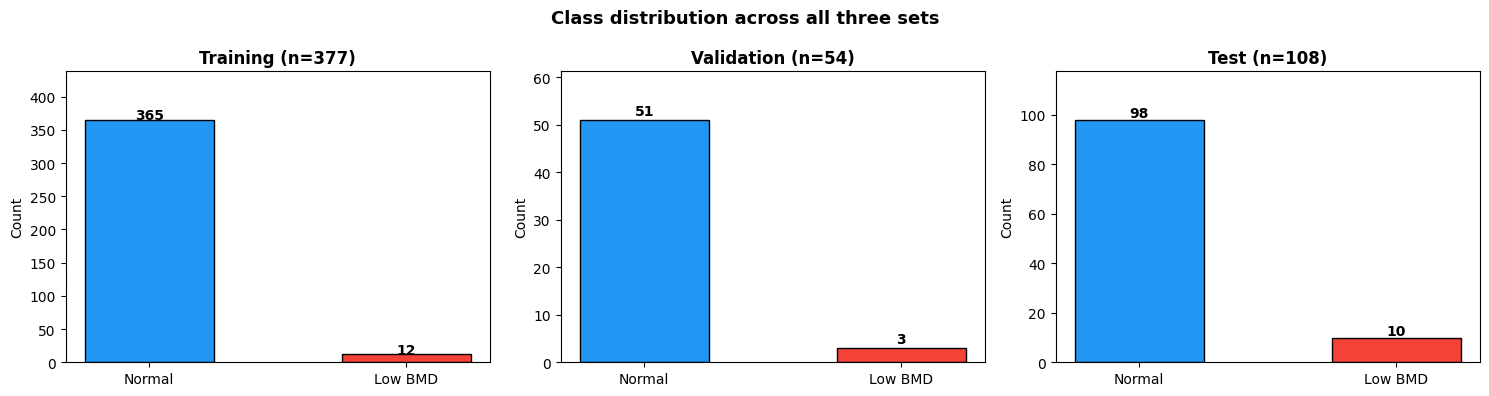

Saved: dataset_distribution.png

Observation: The test set has 10 low BMD samples vs 3 in validation.
This provides a more reliable estimate of the minority class performance.


In [4]:
# Dataset Distribution visualization

fig, axes = plt.subplots(1, 3, figsize=(15,4))
fig.suptitle("Class distribution across all three sets", fontsize=13, fontweight="bold")

for ax, (name, df) in zip(axes, [("Training (n=377)", df_train),
                                 ("Validation (n=54)", df_val),
                                 ("Test (n=108)", df_test)]):
    counts = [sum(df.label==0), sum(df.label ==1)]
    bars = ax.bar(["Normal", "Low BMD"], counts,
                  color=["#2196F3", "#F44336"], edgecolor="black", width=0.5)
    ax.set_title(name, fontweight="bold")
    ax.set_ylabel("Count")
    ax.set_ylim(0, max(counts) *1.2)
    for bar, v in zip(bars, counts):
        ax.text(bar.get_x()+bar.get_width()/2, v+1, str(v),
                ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("dataset_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: dataset_distribution.png")
print()
print("Observation: The test set has 10 low BMD samples vs 3 in validation.")
print("This provides a more reliable estimate of the minority class performance.")



# Section 3 - Feature Extraction

The HOG feature extraction pipeline from assignment one has been improved with the implementation of image resizing to 64*64 prior to HOG extraction, Which guarantees a fixed length feature vector regardless of the original image resolution (which varies from 700x700 to 3000x3000 pixels in this dataset).

## Feature vector composition

Each sample has been represented as:
 [ HOG features (1764 values) | age in years (1) |Gender binary (1) ] = 1766 total features

## Batch Processing

with 377 + 54 + 108 = 539 total images, processing is completed in batches of 50 to avoid RAM overflows.

In [5]:
# Feature extraction functions
GENDER_MAP = {"M": 1, "F": 0}

def load_image_bgr(filename):
    # Load X-ray as BGR array using cv2. Returns None if missing.
    path = os.path.join(IMAGE_DIR, filename)
    if not os.path.exists(path):
        return None
    return cv2.imread(path)

def image_to_feature_vector(image, size=IMG_SIZE):
    # Resize and flatten to 1D pixel vector
    return cv2.resize(image, size).flatten()

def extract_histogram_of_Grad(image):
    # HOG feature extraction
    # Resizing done first to enable fixed output length regardless of input size.
    image_resized = cv2.resize(image, IMG_SIZE)
    gray_image = cv2.cvtColor(image_resized, cv2.COLOR_BGR2GRAY)
    hog_features = hog(
        gray_image,
        orientations=HOG_ORIENTATION,
        pixels_per_cell=HOG_PX_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        visualize=False,
        feature_vector=True
    )
    return hog_features

# Compute exact feature lengths using a dummy image (prevents mismatch issues)
_dummy = np.zeros((*IMG_SIZE, 3), dtype=np.uint8)
HOG_LEN = len(extract_histogram_of_Grad(_dummy))
RAW_LEN = len(image_to_feature_vector(_dummy))

print(f"HOG feature vector length : {HOG_LEN}")
print(f"Raw pixel vector length : {RAW_LEN}")
print(f"Total HOG + Meta per sample: {HOG_LEN + 2}")


HOG feature vector length : 1764
Raw pixel vector length : 12288
Total HOG + Meta per sample: 1766


In [ ]:
# Batch future extraction for all three sets
def build_feature_matrix(df, batch_size=BATCH_SIZE, split_label="?"):
    # Build HOG + metadata feature matrix. Processes in batches to manage RAM
    hog_list = []
    lbl_list = []
    missing = 0
    n = len(df)
    total_batches = (n + batch_size - 1) // batch_size

    for batch_idx in range(total_batches):
        start = batch_idx * batch_size
        end = min(start + batch_size, n)
        batch = df.iloc[start:end]

        for _, row in batch.iterrows():
            img = load_image_bgr(row["image"])
            age_val = row["age_years"]
            sex_val = float(GENDER_MAP.get(str(row["Gender"]).upper(), 0))

            if img is not None:
                # Force 3 channel (some X-rays load as greyscale)
                if len(img.shape) == 2:
                    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                elif img.shape[2] == 1:
                    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                hog_f = extract_histogram_of_Grad(img).astype(np.float32)
            else:
                hog_f = np.zeros(HOG_LEN, dtype=np.float32)
                missing += 1

            meta = np.array([age_val, sex_val], dtype=np.float32)
            hog_list.append(np.concatenate([hog_f, meta]))
            lbl_list.append(int(row["label"]))
        print(f"  [{split_label}] Batch {batch_idx+1}/{total_batches} ({end}/{n})", end="\r")

    print()
    if missing:
        print(f" {missing} image(s) not found. Zero vectors used.")
    return np.array(hog_list), np.array(lbl_list)

print("Extracting training features..")
X_train_raw, y_train = build_feature_matrix(df_train, split_label="TRAIN")

print("Extracting validation features..")
X_val_raw, y_val = build_feature_matrix(df_val, split_label="VAL")

print("Extracting test features..")
X_test_raw, y_test = build_feature_matrix(df_test, split_label="TEST")

print()
print(f"Training : {X_train_raw.shape} labels: Normal={sum(y_train==0)}, LowBMD={sum(y_train==1)}")
print(f"Validation : {X_val_raw.shape} labels: Normal={sum(y_val==0)}, LowBMD={sum(y_val==1)}")
print(f"Testing : {X_test_raw.shape} labels: Normal={sum(y_test==0)}, LowBMD={sum(y_test==1)}")


Extracting training features..
  [TRAIN] Batch 8/8 (377/377)
Extracting validation features..
  [VAL] Batch 2/2 (54/54)
Extracting test features..
  [TEST] Batch 3/3 (108/108)

Training : (377, 1766) labels: Normal=365, LowBMD=12
Validation : (54, 1766) labels: Normal=51, LowBMD=3
Training : (108, 1766) labels: Normal=98, LowBMD=10


In [ ]:
# Feature Scaling (StandardScaler)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw) #fit and transform on train
X_val_scaled = scaler.transform(X_val_raw) # Transform only
X_test_scaled = scaler.transform(X_test_raw) # Transform only

print("StandardScaler applied (training set only)")
print(f"Training scaled - mean: {X_train_scaled.mean():.5f} | std: {X_train_scaled.std():.5f}")
print(f"Validation scaled - mean: {X_val_scaled.mean():.5f} | std: {X_val_scaled.std():.5f}")
print(f"Test scaled - mean: {X_test_scaled.mean():.5f} | std: {X_test_scaled.std():.5f}")
print()
print("Scaler fitted onto training set only. Val and test use training statistics.")

StandardScaler applied (training set only)
Training scaled - mean: -0.00000 | std: 1.00000
Validation scaled - mean: -0.00815 | std: 0.99115
Test scaled - mean: -0.01861 | std: 0.99722

Scaler fitted onto training set only. Val and test use training statistics.


# Section 4 - Baseline Random Forest Refinement

## Purpose

Assignment 1 used a fixed RF configuration evaluated only on the validation set. The following section refines the baseline by: 
1. Systematically searching hyper parameters
2. Using the threshold sweep to maximize low BMD Recall
3. Evaluating the best overall configuration on all three sets (train/val/test)

## Hyperparameters tuned

- n_estimators : Number of trees in the ensemble.
- max_depth : Maximum depth per tree (this controls overfitting).
- min_samples_leaf - minimum samples at each leaf node.

## Primary Metric

Recall for Low BMD remains the primary metric. A missed diagnosis is more harmful than a false alarm.



In [8]:
# Hyperparameter search - RF

print("RF Hyperparameter Search (validated on validation set)")
print(f"{'n_est':>6} {'depth':>6} {'Val Acc%':>10} {'Val rec%':>10} {'Val F1%':>9}")

best_val_recall = -1.0
best_rf_params = {}

for n_est in [100, 200, 300, 500]:
    for depth in [8, 12, 15, None]:
        rf = RandomForestClassifier(
            n_estimators=n_est,
            max_depth=depth,
            min_samples_leaf=1,
            class_weight="balanced",  # Compensates for the 3.2% Minority
            max_features="sqrt",
            random_state=SEED,
            n_jobs=-1
        )
        rf.fit(X_train_scaled, y_train)
        y_val_pred = rf.predict(X_val_scaled)

        acc_v = accuracy_score(y_val, y_val_pred)
        rec_v = recall_score(y_val, y_val_pred, zero_division=0)
        f1_v = f1_score(y_val, y_val_pred, zero_division=0)

        marker = " <-- best" if rec_v > best_val_recall else ""
        depth_str = str(depth) if depth is not None else "None"
        print(" {:>4} {:>5} {:>8.2f}% {:>8.2f}% {:>8.2f}%{}".format(
            n_est, depth_str, acc_v*100, rec_v*100, f1_v*100, marker))
        
        if rec_v > best_val_recall:
            best_val_recall = rec_v
            best_rf_params = {"n_estimators": n_est, "max_depth": depth}

print()
print(f"Best Configuration: {best_rf_params}")
print("Best validation Recall: {:.2f}%".format(best_val_recall * 100))

RF Hyperparameter Search (validated on validation set)
 n_est  depth   Val Acc%   Val rec%   Val F1%
  100     8    94.44%     0.00%     0.00% <-- best
  100    12    94.44%     0.00%     0.00%
  100    15    94.44%     0.00%     0.00%
  100  None    94.44%     0.00%     0.00%
  200     8    94.44%     0.00%     0.00%
  200    12    94.44%     0.00%     0.00%
  200    15    94.44%     0.00%     0.00%
  200  None    94.44%     0.00%     0.00%
  300     8    94.44%     0.00%     0.00%
  300    12    94.44%     0.00%     0.00%
  300    15    94.44%     0.00%     0.00%
  300  None    94.44%     0.00%     0.00%
  500     8    94.44%     0.00%     0.00%
  500    12    94.44%     0.00%     0.00%
  500    15    94.44%     0.00%     0.00%
  500  None    94.44%     0.00%     0.00%

Best Configuration: {'n_estimators': 100, 'max_depth': 8}
Best validation Recall: 0.00%


In [9]:
# Train best RF on full training set

best_rf = RandomForestClassifier(
    n_estimators=best_rf_params["n_estimators"],
    max_depth=best_rf_params["max_depth"],
    min_samples_leaf=1,
    class_weight="balanced",
    max_features='sqrt',
    random_state=SEED,
    n_jobs=-1
)
best_rf.fit(X_train_scaled, y_train)
print("Best RF trained on full training set.")

Best RF trained on full training set.


In [10]:
# Threshold sweep on validation set
# Lowering the decision threshold form 0.5 forces the RF to flag more Low BMD cases.
# This recovers recall ate at the cost of a bit of precision.

y_proba_rf_val = best_rf.predict_proba(X_val_scaled)[:, 1]

print("RF - Low BMD probability stats (validation):")
print(" Max: {:.4f} Min: {:.4f} Mean: {:.4f}".format(
    y_proba_rf_val.max(), y_proba_rf_val.min(), y_proba_rf_val.mean()))

print()

print("Threshold Sweep - best RF on validation set")
print(f"{'Thresh':>8} {'Acc%':>8} {'Rec%':>8} {'Prec%':>9} {'F1%':>8}")

best_thresh_rf = 0.5
best_f1_rf = 0.0

for thresh in [0.50, 0.40, 0.30, 0.20, 0.15, 0.10, 0.05]:
    y_t = (y_proba_rf_val >= thresh).astype(int)
    acc_t = accuracy_score(y_val, y_t)
    rec_t = recall_score(y_val, y_t, zero_division=0)
    pre_t = precision_score(y_val, y_t, zero_division=0)
    f1_t = f1_score(y_val, y_t, zero_division=0)
    marker = " <-- best F1" if f1_t > best_f1_rf else ""
    print("{:>6.2f} {:>7.2f}% {:>7.2f}% {:>8.2f}% {:>7.2f}%{}".format(
        thresh, acc_t*100, rec_t*100, pre_t*100, f1_t*100, marker))
    
    if f1_t > best_f1_rf:
        best_f1_rf = f1_t
        best_thresh_rf = thresh

print()
print(f"Selected threshold: {best_thresh_rf:.2f}")
    

RF - Low BMD probability stats (validation):
 Max: 0.0897 Min: 0.0000 Mean: 0.0316

Threshold Sweep - best RF on validation set
  Thresh     Acc%     Rec%     Prec%      F1%
  0.50   94.44%    0.00%     0.00%    0.00%
  0.40   94.44%    0.00%     0.00%    0.00%
  0.30   94.44%    0.00%     0.00%    0.00%
  0.20   94.44%    0.00%     0.00%    0.00%
  0.15   94.44%    0.00%     0.00%    0.00%
  0.10   94.44%    0.00%     0.00%    0.00%
  0.05   74.07%    0.00%     0.00%    0.00%

Selected threshold: 0.50


In [11]:
# Refined RF evaluation - val and test

y_proba_rf_test = best_rf.predict_proba(X_test_scaled)[:, 1]
y_pred_rf_val = (y_proba_rf_val >= best_thresh_rf).astype(int)
y_pred_rf_test = (y_proba_rf_test >= best_thresh_rf).astype(int)

def print_metrics(y_true, y_pred, label):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f" {label}")
    print("Accuracy : {:.2f}%".format(acc * 100))
    print("Precision: {:.2f}%".format(prec * 100))
    print("Recall   : {:.2f}% <- primary".format(rec * 100))
    print("F1       : {:.2f}%".format(f1 * 100))
    return {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}

print("Refined Random Forest - Final Eval")
print(f"(Threshold={best_thresh_rf:.2f}, {best_rf_params})")
rf_val_metrics = print_metrics(y_val, y_pred_rf_val, "Validation set")
print()
print("Full classification report - Test set:")
print(classification_report(y_test, y_pred_rf_test, target_names=["Normal", "Low BMD"]))

Refined Random Forest - Final Eval
(Threshold=0.50, {'n_estimators': 100, 'max_depth': 8})
 Validation set
Accuracy : 94.44%
Precision: 0.00%
Recall   : 0.00% <- primary
F1       : 0.00%

Full classification report - Test set:
              precision    recall  f1-score   support

      Normal       0.91      1.00      0.95        98
     Low BMD       0.00      0.00      0.00        10

    accuracy                           0.91       108
   macro avg       0.45      0.50      0.48       108
weighted avg       0.82      0.91      0.86       108



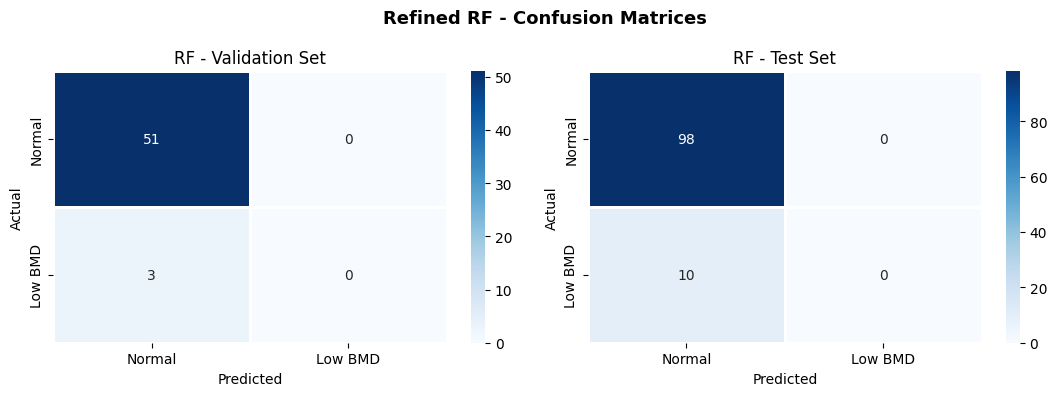

Saved: rf_confusion_matrices.png


In [12]:
# Confusion Matrix - RF on test set
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("Refined RF - Confusion Matrices", fontsize=13, fontweight="bold")

for ax, (y_true, y_pred, title) in zip(axes, [
    (y_val, y_pred_rf_val, "Validation Set"),
    (y_test, y_pred_rf_test, "Test Set")
]):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Low BMD"],
                yticklabels=["Normal", "Low BMD"],
                linewidths=1, linecolor="white")
    ax.set_title(f"RF - {title}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("rf_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: rf_confusion_matrices.png")


# Section 5 - SHallow Neural Network (Design & Architecture)

## What is a shallow neural network

A shallow neural network (also known as a Multi Layer Perceptron or MLP) consists of an input later, a small number of hidden layers, and an output later. Each layer applies a weighted sum followed by a non linear activation function:

```
Input (1766 features) 

 |Dense(64,relu) [hidden layer 1]: Learns complex feature combinations
 |Dense(32,relu) [hidden layer 2]: Further abstraction
 |Dense(1, sigmoid) [output]: Probability of Low BMD (between 0 and 1)

```

## Why this architecture is utilized

- Input Dimension (1766): Matches the HOG + metadata feature vector length
- ReLU activation: Standard for hidden layers (avoids vanishing gradient problem)
- Sigmoid output: Outputs a probability in [0,1] for binary classification
- Binary cross entropy loss: Standard loss for binary classification tasks.

## How class imbalance is handled

The **class_weight** parameter in .fit() assigns a higher loss to Low BMD samples, which forces the network to pay more attention to the minority class during training. This is the NN equivalent of **class_weight='balanced** used in RF baseline.


In [13]:
# Compute class weights for imbalance training

n_total = len(y_train)
n_norm = sum(y_train == 0)
n_low = sum(y_train == 1)

class_weight_0 = n_total / (2 * n_norm) # weight for normal
class_weight_1 = n_total / (2 * n_low) # weight for Low BMD

class_weights = {0: class_weight_0, 1: class_weight_1}

print("Class weights for imbalanced training")
print(f" Normal(class 0): weight = {class_weight_0:.4f}")
print(f" Low BMD(class 1): weight = {class_weight_1:.4f}")
print(f" Ratio: Low BMD is weighted = {class_weight_1/class_weight_0:.1f} x more than normal")

Class weights for imbalanced training
 Normal(class 0): weight = 0.5164
 Low BMD(class 1): weight = 15.7083
 Ratio: Low BMD is weighted = 30.4 x more than normal


In [14]:
# Build MLP model

def build_mlp(input_dim, units_1=64, units_2=32, learning_rate=0.001, seed=SEED):
    # Set reproducibility seeds
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)), # input layer
        layers.Dense(units_1, activation="relu"), # hidden layer 1
        layers.Dense(units_2, activation="relu"), # hidden layer 2
        layers.Dense(1, activation="sigmoid") # output: P(Low BMD)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy", # standard for binary classification
        metrics = ["accuracy"]
    )
    return model

# Build the initial model
input_dim = X_train_scaled.shape[1]
model = build_mlp(input_dim)

print("Model architecture:")
model.summary()


2026-06-05 12:58:34.257554: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-06-05 12:58:34.257798: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-06-05 12:58:34.257854: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-06-05 12:58:34.258527: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-06-05 12:58:34.259042: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model architecture:
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                113088    
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 115201 (450.00 KB)
Trainable params: 115201 (450.00 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


# Section 6 - Neural Network Training

## Training strategy

the training follows the Week 9 Workshop approach:
- **Early Stopping** : Monitors validation loss and stops training when it stops improving, which restores the best weights found during training.
- **Epochs**: Maximum 200, early stopping usually terminates earlier
- **Batch size**: 16 (Smaller batches help with the tiny minority class)
_ **Validation set**: Used during training to track generalization (the training set is not used)

## Training/Validation loss curves

Loss curves show how both training loss and validation change across epochs. A healthy curve will show both decreasing simultaneously. If training loss keeps falling while validation loss rises, the model is overfitting (memorizing training data).

## Threshold tuning for NN

Like the RF baseline, the NN outputs probabilities. The default threshold of 0.5 predicts all Normal due to class imbalance. A threshold sweep is utilized after training to find the value tht maximizes F1 for low BMD. 

In [15]:
# Early stopping callback

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", # watch validation loss (not training loss)
    patience=15, # stop if no improvement for 15 epochs
    restore_best_weights=True # revert to the weights that gave the lowest val_loss
)

print("Early stopping configured:")
print(f" Monitor: val_loss")
print(f" Patience: 15 epochs")
print(f" Action : restore weights from the best epoch")

Early stopping configured:
 Monitor: val_loss
 Patience: 15 epochs
 Action : restore weights from the best epoch


In [16]:
# Train the MLP

print("Training MLP on full training set.")
print()

history = model.fit(
    X_train_scaled, y_train,
    validation_data = (X_val_scaled, y_val), # monitor validation loss each epoch
    epochs=200,
    batch_size=16,
    class_weight=class_weights, # compensate for class imbalance
    callbacks=[early_stop],
    verbose=1
)

print()
print(f"Training completed at epoch {len(history.history['loss'])}")
print(f"Best val_loss: {min(history.history['val_loss']):.4f}")

Training MLP on full training set.

Epoch 1/200


2026-06-05 12:58:34.956241: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.
2026-06-05 12:58:34.986671: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] model_pruner failed: INVALID_ARGUMENT: Graph does not contain terminal node Adam/AssignAddVariableOp.


24/24 [==============================] - 1s 25ms/step - loss: 1.2332 - accuracy: 0.4934 - val_loss: 0.9683 - val_accuracy: 0.6111
Epoch 2/200
24/24 [==============================] - 0s 6ms/step - loss: 0.6332 - accuracy: 0.5836 - val_loss: 1.0612 - val_accuracy: 0.5741
Epoch 3/200
24/24 [==============================] - 0s 6ms/step - loss: 0.4615 - accuracy: 0.6286 - val_loss: 0.7850 - val_accuracy: 0.6111
Epoch 4/200
24/24 [==============================] - 0s 6ms/step - loss: 0.3806 - accuracy: 0.6499 - val_loss: 0.7546 - val_accuracy: 0.6111
Epoch 5/200
24/24 [==============================] - 0s 6ms/step - loss: 0.3341 - accuracy: 0.7135 - val_loss: 0.9966 - val_accuracy: 0.6667
Epoch 6/200
24/24 [==============================] - 0s 6ms/step - loss: 0.5386 - accuracy: 0.6711 - val_loss: 0.6154 - val_accuracy: 0.7037
Epoch 7/200
24/24 [==============================] - 0s 6ms/step - loss: 2.1782 - accuracy: 0.6976 - val_loss: 3.2888 - val_accuracy: 0.3519
Epoch 8/200
24/24 [=====

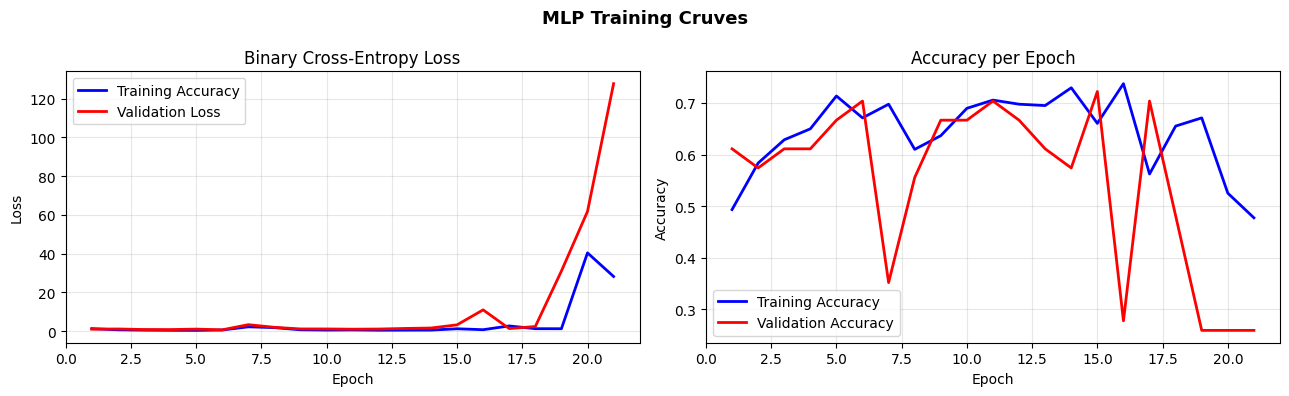

Saved: nn_training_curves.png

Interpreting curves:
 Both loss curves should decrease further together - indicates good generalization.
 If val_loss rises while train_loss falls, model is overfitting.


In [ ]:
# Training and validation loss/accuracy curves

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("MLP Training Curves", fontsize=13, fontweight="bold")

epochs_ran = range(1, len(history.history["loss"]) + 1)

# Loss curve
axes[0].plot(epochs_ran, history.history["loss"], "b-", lw=2, label="Training Accuracy")
axes[0].plot(epochs_ran, history.history["val_loss"], "r-", lw=2, label="Validation Loss")
axes[0].set_title("Binary Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy Curve
axes[1].plot(epochs_ran, history.history["accuracy"],     "b-", lw=2, label="Training Accuracy")
axes[1].plot(epochs_ran, history.history["val_accuracy"], "r-", lw=2, label="Validation Accuracy")
axes[1].set_title("Accuracy per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("nn_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: nn_training_curves.png")
print()
print("Interpreting curves:")
print(" Both loss curves should decrease further together - indicates good generalization.")
print(" If val_loss rises while train_loss falls, model is overfitting.")


In [18]:
# NN threshold sweep on validation set
y_proba_nn_val = model.predict(X_val_scaled, verbose=0).flatten()

print("NN - Low BMD probability stats (validation): ")
print(" Max: {:.4f} Min: {:.4f} Mean: {:.4f}".format(
    y_proba_nn_val.max(), y_proba_nn_val.min(), y_proba_nn_val.mean()
))
print()

print("Threshold Sweep - MLP on validation set")
print(f"{'Thresh':>8} {'Acc%':>8} {'Rec%':>8} {'Prec%':>9} {'F1%':>8}")

best_thresh_nn = 0.5
best_f1_nn = 0.0

for thresh in [0.50, 0.40, 0.30, 0.20, 0.15, 0.10, 0.05]:
    y_t = (y_proba_nn_val >= thresh).astype(int)
    acc_t = accuracy_score(y_val, y_t)
    rec_t = recall_score(y_val,    y_t, zero_division=0)
    pre_t = precision_score(y_val, y_t, zero_division=0)
    f1_t  = f1_score(y_val,        y_t, zero_division=0)
    marker = "  <-- best F1" if f1_t > best_f1_nn else ""
    print("  {:>6.2f}  {:>7.2f}%  {:>7.2f}%  {:>8.2f}%  {:>7.2f}%{}".format(
          thresh, acc_t*100, rec_t*100, pre_t*100, f1_t*100, marker))
    if f1_t > best_f1_nn:
        best_f1_nn     = f1_t
        best_thresh_nn = thresh

print()
print(f"Selected NN threshold: {best_thresh_nn:.2f}")


NN - Low BMD probability stats (validation): 
 Max: 0.9751 Min: 0.0012 Mean: 0.3449

Threshold Sweep - MLP on validation set
  Thresh     Acc%     Rec%     Prec%      F1%
    0.50    70.37%    33.33%      6.67%    11.11%  <-- best F1
    0.40    66.67%    66.67%     10.53%    18.18%  <-- best F1
    0.30    55.56%   100.00%     11.11%    20.00%  <-- best F1
    0.20    46.30%   100.00%      9.38%    17.14%
    0.15    40.74%   100.00%      8.57%    15.79%
    0.10    31.48%   100.00%      7.50%    13.95%
    0.05    24.07%   100.00%      6.82%    12.77%

Selected NN threshold: 0.30


# Section 7 - Neural Network Hyperparameter Tuning

the following hyperparameters are systemetically tested on the validation set:

|Hyperparameter | Values | Effect |
|---------------|--------|--------|
| Hidden units (layer 1) | 32, 64, 128 | Larger = more capacity, slower|
| Hidden units (layer 2) | 16, 32, 64 | Second layer abstraction|
| Learning rate | 0.001, 0.01 | Controls step size during optimization |

With a small set and long training times, an elongated grid search is not logical. A target manual search over the most impactful parameters is the most optimal approach for this task size

Selection criteria: The configuration with the highest validation F1 score for Low BMD is selected as the final model, since F1 balances Recall and Precision under class imbalance.

In [19]:
# Hyperparameter search
print("MLP Hyperparameter Search (validated on validation set)")
print(f"{'Units1':>7} {'Units2':>7} {'LR':>7} {'Val Rec%':>10} {'Val F1%':>9}")

best_nn_val_f1     = 0.0
best_nn_params     = {}
best_nn_model      = None
best_nn_thresh     = 0.5
all_nn_results     = []

# Loop over hyperparameter combinations 
for units_1 in [32, 64, 128]:
    for units_2 in [16, 32, 64]:
        for lr in [0.001, 0.01]:

            m = build_mlp(input_dim, units_1=units_1, units_2=units_2,
                          learning_rate=lr, seed=SEED)
            es = keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=10, restore_best_weights=True)

            m.fit(X_train_scaled, y_train,
                  validation_data=(X_val_scaled, y_val),
                  epochs=100, batch_size=16,
                  class_weight=class_weights,
                  callbacks=[es], verbose=0)

            proba = m.predict(X_val_scaled, verbose=0).flatten()
            best_f1_this, best_t_this = 0.0, 0.5
            for t in [0.50, 0.40, 0.30, 0.20, 0.15, 0.10, 0.05]:
                y_t  = (proba >= t).astype(int)
                f1_t = f1_score(y_val, y_t, zero_division=0)
                if f1_t > best_f1_this:
                    best_f1_this = f1_t
                    best_t_this  = t

            rec_v = recall_score(y_val, (proba >= best_t_this).astype(int), zero_division=0)
            marker = " <-- best" if best_f1_this > best_nn_val_f1 else ""
            print("  {:>5}   {:>5}   {:>5.3f}   {:>8.2f}%   {:>8.2f}%{}".format(
                  units_1, units_2, lr, rec_v*100, best_f1_this*100, marker))

            all_nn_results.append({
                "units_1": units_1, "units_2": units_2, "lr": lr,
                "val_f1": best_f1_this, "val_rec": rec_v, "thresh": best_t_this
            })

            if best_f1_this > best_nn_val_f1:
                best_nn_val_f1 = best_f1_this
                best_nn_params = {"units_1": units_1, "units_2": units_2, "lr": lr}
                best_nn_model  = m
                best_nn_thresh = best_t_this

print()
print(f"Best NN config: {best_nn_params}")
print("Best val F1  : {:.2f}%  at threshold {:.2f}".format(
      best_nn_val_f1*100, best_nn_thresh))


MLP Hyperparameter Search (validated on validation set)
 Units1  Units2      LR   Val Rec%   Val F1%


     32      16   0.001      66.67%      17.39% <-- best


     32      16   0.010      66.67%      10.81%


     32      32   0.001      66.67%      28.57% <-- best


     32      32   0.010      66.67%      12.12%


     32      64   0.001      66.67%      19.05%


... (8 outputs left out)

    128      16   0.010      33.33%       5.00%


    128      32   0.001     100.00%      21.43%


    128      32   0.010      33.33%       5.00%


    128      64   0.001      66.67%      20.00%
    128      64   0.010     100.00%      14.63%

Best NN config: {'units_1': 32, 'units_2': 32, 'lr': 0.001}
Best val F1  : 28.57%  at threshold 0.50


In [20]:
#  Retrain the best NN configuration for final model
print("Retraining best NN config.")

final_nn = build_mlp(
    input_dim,
    units_1=best_nn_params["units_1"],
    units_2=best_nn_params["units_2"],
    learning_rate=best_nn_params["lr"],
    seed=SEED
)

es_final = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True)

history_final = final_nn.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200, batch_size=16,
    class_weight=class_weights,
    callbacks=[es_final],
    verbose=1
)

print()
print(f"Final NN trained for {len(history_final.history['loss'])} epochs.")

Retraining best NN config.
Epoch 1/200
24/24 [==============================] - 1s 21ms/step - loss: 1.2605 - accuracy: 0.4854 - val_loss: 0.8801 - val_accuracy: 0.6481
Epoch 2/200
24/24 [==============================] - 0s 6ms/step - loss: 0.5477 - accuracy: 0.5517 - val_loss: 0.7052 - val_accuracy: 0.6667
Epoch 3/200
24/24 [==============================] - 0s 6ms/step - loss: 0.4663 - accuracy: 0.5703 - val_loss: 0.6088 - val_accuracy: 0.7037
Epoch 4/200
24/24 [==============================] - 0s 7ms/step - loss: 0.3801 - accuracy: 0.6366 - val_loss: 0.5509 - val_accuracy: 0.7037
Epoch 5/200
24/24 [==============================] - 0s 6ms/step - loss: 0.3426 - accuracy: 0.6472 - val_loss: 0.5563 - val_accuracy: 0.7222
Epoch 6/200
24/24 [==============================] - 0s 6ms/step - loss: 0.3097 - accuracy: 0.7162 - val_loss: 0.6323 - val_accuracy: 0.6852
Epoch 7/200
24/24 [==============================] - 0s 7ms/step - loss: 0.3983 - accuracy: 0.6950 - val_loss: 0.8793 - val_ac

# Section 8 - Evaluation & Model Comparison

(Both models are evaluated on the same test set using the same metrics. This is the only way to make a fair comparison)

The test set (n=108, 10 Low BMD) was not used at any point during model development or hyperparameter tuning. it is used once for the final reporting

## Metrics reported

At minimum, three metrics are compared as required: Accuracy, Recall (Low BMD), Precision (Low BMD), F1 (Low BMD).

High accuracy with zero Recall means the model is predicting all Normal. Recall and F1 for low BMD are the clinically correct metrics.

In [21]:
# Final predictions on test set 

# NN predictions
y_proba_nn_test = final_nn.predict(X_test_scaled, verbose=0).flatten()
y_pred_nn_test = (y_proba_nn_test >= best_nn_thresh).astype(int)

# RF predictions (already computed in Section 4)


print("Final Test Set Results — All Models")
print("(Test set was 'Not' used during development)")


rf_test = print_metrics(y_test, y_pred_rf_test, "Refined RF Baseline")
print()
nn_test = print_metrics(y_test, y_pred_nn_test, "Shallow NN (MLP)")
print()
print("Full classification report — NN on Test set:")
print(classification_report(y_test, y_pred_nn_test,
                             target_names=["Normal", "Low BMD"]))


Final Test Set Results — All Models
(Test set was 'Not' used during development)
 Refined RF Baseline
Accuracy : 90.74%
Precision: 0.00%
Recall   : 0.00% <- primary
F1       : 0.00%

 Shallow NN (MLP)
Accuracy : 66.67%
Precision: 3.57%
Recall   : 10.00% <- primary
F1       : 5.26%

Full classification report — NN on Test set:
              precision    recall  f1-score   support

      Normal       0.89      0.72      0.80        98
     Low BMD       0.04      0.10      0.05        10

    accuracy                           0.67       108
   macro avg       0.46      0.41      0.43       108
weighted avg       0.81      0.67      0.73       108



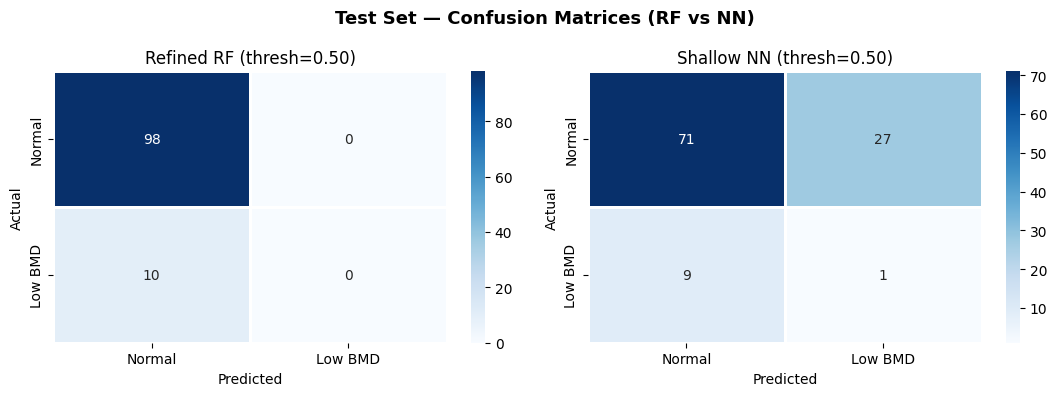

Saved: final_confusion_matrices.png


In [22]:
# Confusion matrices (both models on test set)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("Test Set — Confusion Matrices (RF vs NN)", fontsize=13, fontweight="bold")

for ax, (y_pred, title) in zip(axes, [
    (y_pred_rf_test, f"Refined RF (thresh={best_thresh_rf:.2f})"),
    (y_pred_nn_test, f"Shallow NN (thresh={best_nn_thresh:.2f})")
]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal","Low BMD"],
                yticklabels=["Normal","Low BMD"],
                linewidths=1, linecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("final_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_confusion_matrices.png")

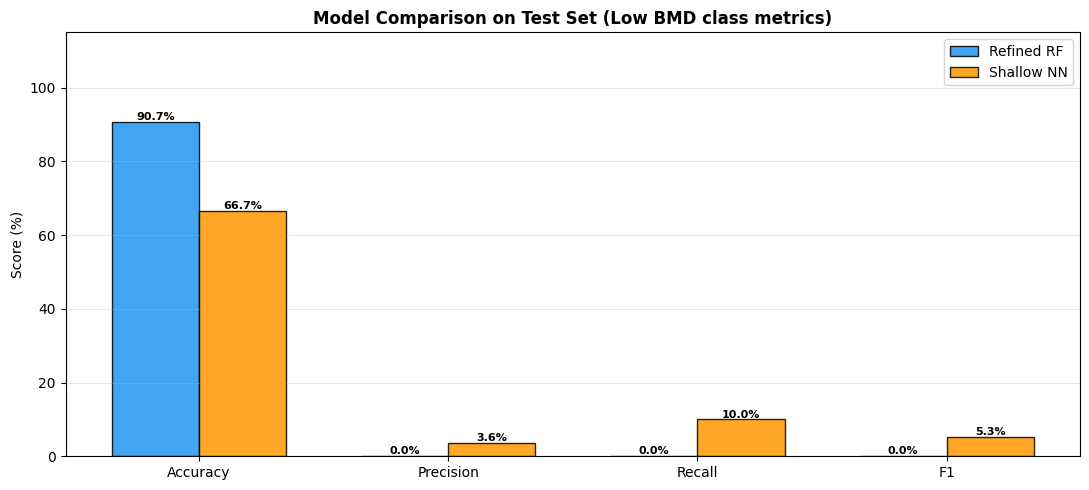

Saved: model_comparison_test.png


In [23]:
# Metric comparison bar chart 
metrics = ["Accuracy", "Precision", "Recall", "F1"]
rf_vals = [rf_test[m] * 100 for m in metrics]
nn_vals = [nn_test[m] * 100 for m in metrics]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars_rf = ax.bar(x - width/2, rf_vals, width, label="Refined RF", color="#2196F3", edgecolor="black", alpha=0.85)
bars_nn = ax.bar(x + width/2, nn_vals, width, label="Shallow NN", color="#FF9800", edgecolor="black", alpha=0.85)

for bars in [bars_rf, bars_nn]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x()+bar.get_width()/2, h+0.5,
                "{:.1f}%".format(h), ha="center", fontsize=8, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 115)
ax.set_ylabel("Score (%)")
ax.set_title("Model Comparison on Test Set (Low BMD class metrics)",
             fontsize=12, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("model_comparison_test.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: model_comparison_test.png")


In [24]:
# Summary results table 

print("Summary Comparison Table — Test Set Performance")
print(f"{'Model':25s} {'Accuracy':>10} {'Precision':>11} {'Recall':>8} {'F1':>8}")
for name, metrics_dict in [("Refined RF Baseline", rf_test), ("Shallow NN (MLP)", nn_test)]:
    print("  {:23s}  {:>8.2f}%  {:>9.2f}%  {:>6.2f}%  {:>6.2f}%".format(
          name,
          metrics_dict["Accuracy"]*100,
          metrics_dict["Precision"]*100,
          metrics_dict["Recall"]*100,
          metrics_dict["F1"]*100))
    
print()
print("Primary metric: Recall (Low BMD) — a missed diagnosis is ")
print("more harmful than a false positive.")

Summary Comparison Table — Test Set Performance
Model                       Accuracy   Precision   Recall       F1
  Refined RF Baseline         90.74%       0.00%    0.00%    0.00%
  Shallow NN (MLP)            66.67%       3.57%   10.00%    5.26%

Primary metric: Recall (Low BMD) — a missed diagnosis is 
more harmful than a false positive.


In [25]:
# Save the raw probabilities for ensemble integration
# This exports the soft probabilities for this NN so that the group can
# combine them with other individual NNs in the ensemble notebook.

import pandas as pd

ensemble_output = pd.DataFrame({
    'image' : df_test['image'].values,
    'true_label' : y_test,
    'nn_prob_lowbmd': y_proba_nn_test,
    'nn_pred': y_pred_nn_test
})

ensemble_output.to_csv('earan_individual_nn_predictions.csv', index=False)
print('Saved: earan_indiviudal_nn_predictions.csv')
print('file contains raw probabilities for ensemble integration')
print(ensemble_output.head(10).to_string(index=False))


Saved: earan_indiviudal_nn_predictions.csv
file contains raw probabilities for ensemble integration
                         image  true_label  nn_prob_lowbmd  nn_pred
6.E.1_9095839_20090409_001.png           0        0.008508        0
6.C.1_9100862_20090219_001.png           0        0.777555        1
6.C.1_9107980_20090225_001.png           1        0.002260        0
6.E.1_9266274_20100415_001.png           0        0.022282        0
6.E.1_9295400_20100510_001.png           0        0.000151        0
6.E.1_9304828_20100519_001.png           0        0.508799        1
6.E.1_9441861_20100528_001.png           1        0.000115        0
6.E.1_9469318_20100323_001.png           0        0.300498        0
6.E.1_9473302_20090825_001.png           0        0.601889        1
6.E.1_9508335_20090602_001.png           0        0.332421        0


# Summary & Key Observations

1. Three set evaluation protocol (train/val/test) provides a rigorous and fair foundation for comparing the RF baseline against the shallow neural network. Both models were evaluated with the same test set.

2. Class imbalance (3.2% Low BMD in training) remains the main challenge. Both models use adequate compensation to accommodate this issue: class_weight='balanced' for RF and class_weight dictionary in .fit() for the NN. Threshold tuning is utilized in both to maximize Recall for minority classes.

3. The shallow NN (MLP with 2 hidden layers) offers a good approach to the RF baseline. Early stopping prevents overfitting given the small dataset size.

4. HOG features (1764 values) remains as the primary input in both models, supported  by age and gender. The feature pipeline is shared, which ensures the comparison isolates the models contribution to differences in performance.
